# CampusFit – Fitness Tracking and Dropout Risk Prediction

**Student Names:** Tanisha Yadav  AND Srishti
**Roll Numbers:** 24CSU214 AND 24CSU205
**Project Title:** CampusFit – Fitness Tracking and Dropout Risk Prediction

## Project Overview

CampusFit is a machine learning project that analyses fitness-related user data to understand fitness behaviour, predict calories burned, and classify users according to their dropout risk.

## Problem Statement

Maintaining consistent fitness habits can be challenging. This project uses machine learning techniques to analyse user activity and fitness information, estimate calories burned, and predict the likelihood of users discontinuing their fitness routines.

## Project Objectives

1. Analyse fitness and lifestyle-related data.
2. Perform data preprocessing and exploratory data analysis.
3. Identify important features influencing dropout risk.
4. Predict calories burned using regression techniques.
5. Classify users based on dropout risk using classification algorithms.
6. Compare model performance using suitable evaluation metrics.

## Dataset Description

The project uses a synthetic CampusFit dataset containing 10,000 records and 30 original columns.

The dataset includes information about:
- User demographics: Age, Gender, Height and Weight.
- Physical activity: Daily Steps, Workout Days and Workout Duration.
- Health and lifestyle: BMI, Sleep Hours, Stress Level and Water Intake.
- Nutrition: Daily Calories, Protein, Carbohydrates and Fat.
- Fitness information: Fitness Goal, Fitness Level and Workout Type.

**Target Variables:**
- `Calories_Burned` – Regression target.
- `Dropout_Risk` – Classification target.

## Data understanding and exploration

In [1]:
# Importing necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the dataset
df=pd.read_csv("CampusFit_Synthetic_Dataset_10000.csv")
df.head()

,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Goal,Activity_Level,Daily_Steps,Workout_Days,...,Mood,Heart_Rate,Body_Fat_Percent,Fitness_Level,Workout_Type,Recommended_Diet,Hydration_Status,Reward_Points,Streak_Days,Dropout_Risk
0,1001,28,Male,151.0,51.1,22.4,Weight Loss,Low,5016,2,...,Low,94,19.7,Beginner,Yoga,Calorie Deficit,Low,1540,150,Low
1,1002,30,Male,177.9,74.1,23.4,Weight Loss,Low,5920,0,...,Neutral,67,23.9,Beginner,Yoga,Calorie Deficit,Good,200,20,Low
2,1003,27,Female,173.1,87.8,29.3,Weight Loss,High,12370,5,...,Neutral,64,27.0,Advanced,Strength,Calorie Deficit,Good,1460,136,Low
3,1004,25,Female,160.8,84.8,32.8,Stay Fit,High,12656,5,...,Neutral,91,28.9,Advanced,Yoga,Balanced,Good,460,36,Low
4,1005,21,Female,179.9,80.6,24.9,Stay Fit,Moderate,6898,4,...,Happy,84,21.7,Intermediate,Yoga,Balanced,Good,1430,135,Low


In [3]:
df.tail()   #bottom 5

,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Goal,Activity_Level,Daily_Steps,Workout_Days,...,Mood,Heart_Rate,Body_Fat_Percent,Fitness_Level,Workout_Type,Recommended_Diet,Hydration_Status,Reward_Points,Streak_Days,Dropout_Risk
9995,10996,25,Female,188.0,66.4,18.8,Muscle Gain,Low,5477,2,...,Neutral,91,18.9,Beginner,Cardio,High Protein,Low,1320,128,Low
9996,10997,20,Male,150.0,44.1,19.6,Weight Loss,Moderate,6083,4,...,Low,95,15.5,Intermediate,HIIT,Calorie Deficit,Low,250,17,Medium
9997,10998,24,Female,180.6,90.0,27.6,Muscle Gain,Low,4853,1,...,Low,73,24.2,Beginner,HIIT,High Protein,Good,380,36,Low
9998,10999,18,Female,183.5,85.5,25.4,Stay Fit,High,12514,5,...,Neutral,65,25.6,Advanced,Strength,Balanced,Good,540,44,Low
9999,11000,23,Female,165.0,65.3,24.0,Weight Loss,High,17214,6,...,Neutral,87,22.2,Advanced,HIIT,Calorie Deficit,Good,1760,164,Low


In [4]:
df.sample(5)   #random 5 records

,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Goal,Activity_Level,Daily_Steps,Workout_Days,...,Mood,Heart_Rate,Body_Fat_Percent,Fitness_Level,Workout_Type,Recommended_Diet,Hydration_Status,Reward_Points,Streak_Days,Dropout_Risk
8934,9935,23,Female,158.2,58.1,23.2,Weight Loss,High,12194,6,...,Low,67,23.3,Advanced,Mixed,Calorie Deficit,Low,1480,136,Low
6130,7131,18,Male,187.7,69.1,19.6,Stay Fit,Low,3771,2,...,Low,81,14.9,Beginner,Strength,Balanced,Low,950,91,Low
9224,10225,30,Male,182.6,76.0,22.8,Weight Loss,Low,5128,2,...,Neutral,94,22.7,Beginner,Mixed,Calorie Deficit,Good,1390,135,Low
9560,10561,25,Male,174.4,103.1,33.9,Weight Loss,High,10137,5,...,Neutral,69,28.2,Advanced,Cardio,Calorie Deficit,Good,200,10,Medium
1091,2092,22,Female,181.8,104.1,31.5,Stay Fit,Moderate,6723,4,...,Happy,87,25.7,Intermediate,Cardio,Balanced,Good,940,86,Low


In [5]:
# Shape of the Dataset
print("Number of Rows",df.shape[0])
print("Number of columns",df.shape[1])
print("Complete Dataset",df.shape)

Number of Rows 10000
Number of columns 30
Complete Dataset (10000, 30)


In [6]:
# Data type 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               10000 non-null  int64  
 1   Age                   10000 non-null  int64  
 2   Gender                10000 non-null  object 
 3   Height_cm             10000 non-null  float64
 4   Weight_kg             10000 non-null  float64
 5   BMI                   10000 non-null  float64
 6   Fitness_Goal          10000 non-null  object 
 7   Activity_Level        10000 non-null  object 
 8   Daily_Steps           10000 non-null  int64  
 9   Workout_Days          10000 non-null  int64  
 10  Workout_Duration_Min  10000 non-null  int64  
 11  Calories_Burned       10000 non-null  int64  
 12  Sleep_Hours           10000 non-null  float64
 13  Stress_Level          10000 non-null  int64  
 14  Water_Intake_L        10000 non-null  float64
 15  Diet_Type           

In [7]:
# Data type of each column
print(df.dtypes)

User_ID                   int64
Age                       int64
Gender                   object
Height_cm               float64
Weight_kg               float64
BMI                     float64
Fitness_Goal             object
Activity_Level           object
Daily_Steps               int64
Workout_Days              int64
Workout_Duration_Min      int64
Calories_Burned           int64
Sleep_Hours             float64
Stress_Level              int64
Water_Intake_L          float64
Diet_Type                object
Daily_Calories            int64
Protein_g                 int64
Carbs_g                   int64
Fat_g                     int64
Mood                     object
Heart_Rate                int64
Body_Fat_Percent        float64
Fitness_Level            object
Workout_Type             object
Recommended_Diet         object
Hydration_Status         object
Reward_Points             int64
Streak_Days               int64
Dropout_Risk             object
dtype: object


In [8]:
#Summary statistics
df.describe()

,User_ID,Age,Height_cm,Weight_kg,BMI,Daily_Steps,Workout_Days,Workout_Duration_Min,Calories_Burned,Sleep_Hours,Stress_Level,Water_Intake_L,Daily_Calories,Protein_g,Carbs_g,Fat_g,Heart_Rate,Body_Fat_Percent,Reward_Points,Streak_Days
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,6000.50000,23.941100,170.009570,75.508190,26.008960,8602.56850,3.643000,54.87300,878.330000,7.257230,5.529000,2.973120,2401.057800,110.078800,264.926800,64.884600,77.512900,23.391210,976.746000,90.38860
std,2886.89568,3.743345,11.543557,16.850953,4.599663,4406.37234,2.213513,20.45841,231.882235,1.018162,2.889082,0.614398,462.964085,29.185191,49.424094,14.729881,10.461853,4.474295,520.187361,51.85187
min,1001.00000,18.000000,150.000000,40.800000,18.000000,2001.00000,0.000000,20.00000,325.000000,5.500000,1.000000,1.500000,1600.000000,60.000000,180.000000,40.000000,60.000000,13.200000,0.000000,0.00000
25%,3500.75000,21.000000,160.000000,62.900000,22.100000,4965.25000,2.000000,37.00000,707.000000,6.400000,3.000000,2.500000,1992.000000,85.000000,222.000000,52.000000,68.000000,19.900000,530.000000,46.00000
50%,6000.50000,24.000000,169.900000,74.000000,26.000000,7912.00000,4.000000,55.00000,869.000000,7.300000,6.000000,2.900000,2405.000000,110.000000,265.000000,65.000000,78.000000,23.400000,970.000000,90.00000
75%,8500.25000,27.000000,180.300000,87.300000,29.900000,11838.00000,5.000000,73.00000,1040.000000,8.100000,8.000000,3.400000,2805.000000,136.000000,308.000000,78.000000,87.000000,26.900000,1430.000000,135.00000
max,11000.00000,30.000000,190.000000,122.400000,34.000000,18000.00000,7.000000,90.00000,1546.000000,9.000000,10.000000,5.000000,3200.000000,160.000000,350.000000,90.000000,95.000000,33.600000,1940.000000,180.00000


In [9]:
# Summary statistics for all columns

df.describe(include='all')

,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Goal,Activity_Level,Daily_Steps,Workout_Days,...,Mood,Heart_Rate,Body_Fat_Percent,Fitness_Level,Workout_Type,Recommended_Diet,Hydration_Status,Reward_Points,Streak_Days,Dropout_Risk
count,10000.00000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000,10000,10000.00000,10000.000000,...,10000,10000.000000,10000.000000,10000,10000,10000,10000,10000.000000,10000.00000,10000
unique,NaN,NaN,2,NaN,NaN,NaN,3,3,NaN,NaN,...,3,NaN,NaN,3,5,3,2,NaN,NaN,3
top,NaN,NaN,Female,NaN,NaN,NaN,Stay Fit,Low,NaN,NaN,...,Low,NaN,NaN,Advanced,Yoga,Balanced,Good,NaN,NaN,Low
freq,NaN,NaN,5014,NaN,NaN,NaN,3381,3381,NaN,NaN,...,5017,NaN,NaN,4414,2021,3381,7877,NaN,NaN,8969
mean,6000.50000,23.941100,NaN,170.009570,75.508190,26.008960,NaN,NaN,8602.56850,3.643000,...,NaN,77.512900,23.391210,NaN,NaN,NaN,NaN,976.746000,90.38860,NaN
std,2886.89568,3.743345,NaN,11.543557,16.850953,4.599663,NaN,NaN,4406.37234,2.213513,...,NaN,10.461853,4.474295,NaN,NaN,NaN,NaN,520.187361,51.85187,NaN
min,1001.00000,18.000000,NaN,150.000000,40.800000,18.000000,NaN,NaN,2001.00000,0.000000,...,NaN,60.000000,13.200000,NaN,NaN,NaN,NaN,0.000000,0.00000,NaN
25%,3500.75000,21.000000,NaN,160.000000,62.900000,22.100000,NaN,NaN,4965.25000,2.000000,...,NaN,68.000000,19.900000,NaN,NaN,NaN,NaN,530.000000,46.00000,NaN
50%,6000.50000,24.000000,NaN,169.900000,74.000000,26.000000,NaN,NaN,7912.00000,4.000000,...,NaN,78.000000,23.400000,NaN,NaN,NaN,NaN,970.000000,90.00000,NaN
75%,8500.25000,27.000000,NaN,180.300000,87.300000,29.900000,NaN,NaN,11838.00000,5.000000,...,NaN,87.000000,26.900000,NaN,NaN,NaN,NaN,1430.000000,135.00000,NaN


In [10]:
# Check missing values
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})
print(missing_summary)


                      Missing Count  Missing Percentage
User_ID                           0                 0.0
Age                               0                 0.0
Gender                            0                 0.0
Height_cm                         0                 0.0
Weight_kg                         0                 0.0
BMI                               0                 0.0
Fitness_Goal                      0                 0.0
Activity_Level                    0                 0.0
Daily_Steps                       0                 0.0
Workout_Days                      0                 0.0
Workout_Duration_Min              0                 0.0
Calories_Burned                   0                 0.0
Sleep_Hours                       0                 0.0
Stress_Level                      0                 0.0
Water_Intake_L                    0                 0.0
Diet_Type                         0                 0.0
Daily_Calories                    0             

In [11]:
# Select columns that contain missing values
missing_columns = missing_summary[
    missing_summary['Missing Count'] > 0
]

print("Columns containing missing values:")
print(missing_columns)

Columns containing missing values:
Empty DataFrame
Columns: [Missing Count, Missing Percentage]
Index: []


In [12]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nCategorical Columns:")
print(categorical_columns)

print("\nTotal Numerical Columns:", len(numerical_columns))
print("Total Categorical Columns:", len(categorical_columns))


Numerical Columns:
['User_ID', 'Age', 'Height_cm', 'Weight_kg', 'BMI', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Heart_Rate', 'Body_Fat_Percent', 'Reward_Points', 'Streak_Days']

Categorical Columns:
['Gender', 'Fitness_Goal', 'Activity_Level', 'Diet_Type', 'Mood', 'Fitness_Level', 'Workout_Type', 'Recommended_Diet', 'Hydration_Status', 'Dropout_Risk']

Total Numerical Columns: 20
Total Categorical Columns: 10


In [13]:
# Display unique values in categorical columns
for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].unique())
    print("Number of unique values:", df[column].nunique())



Column: Gender
Unique values: ['Male' 'Female']
Number of unique values: 2

Column: Fitness_Goal
Unique values: ['Weight Loss' 'Stay Fit' 'Muscle Gain']
Number of unique values: 3

Column: Activity_Level
Unique values: ['Low' 'High' 'Moderate']
Number of unique values: 3

Column: Diet_Type
Unique values: ['Non-Veg' 'Veg']
Number of unique values: 2

Column: Mood
Unique values: ['Low' 'Neutral' 'Happy']
Number of unique values: 3

Column: Fitness_Level
Unique values: ['Beginner' 'Advanced' 'Intermediate']
Number of unique values: 3

Column: Workout_Type
Unique values: ['Yoga' 'Strength' 'Mixed' 'Cardio' 'HIIT']
Number of unique values: 5

Column: Recommended_Diet
Unique values: ['Calorie Deficit' 'Balanced' 'High Protein']
Number of unique values: 3

Column: Hydration_Status
Unique values: ['Low' 'Good']
Number of unique values: 2

Column: Dropout_Risk
Unique values: ['Low' 'Medium' 'High']
Number of unique values: 3


From this we are able to understand 
- Binary: Two categories.
- Ordinal: Categories with a meaningful order.
- Nominal: Categories without a meaningful order.

Binary
3 columns
Gender, Diet_Type, Hydration_Status

Nominal
3 columns
Fitness_Goal, Workout_Type, Recommended_Diet

Ordinal
4 columns
Activity_Level, Mood, Fitness_Level, Dropout_Risk

In [14]:
# Binary categorical columns
binary_columns = [
    'Gender',
    'Diet_Type',
    'Hydration_Status'
]

# Nominal categorical columns
nominal_columns = [
    'Fitness_Goal',
    'Workout_Type',
    'Recommended_Diet'
]

# Ordinal categorical columns
ordinal_columns = [
    'Activity_Level',
    'Mood',
    'Fitness_Level',
    'Dropout_Risk'
]
print("Binary Columns:", binary_columns)
print("Nominal Columns:", nominal_columns)
print("Ordinal Columns:", ordinal_columns)

Binary Columns: ['Gender', 'Diet_Type', 'Hydration_Status']
Nominal Columns: ['Fitness_Goal', 'Workout_Type', 'Recommended_Diet']
Ordinal Columns: ['Activity_Level', 'Mood', 'Fitness_Level', 'Dropout_Risk']


In [15]:
# Binary encoding
binary_mappings = {
    'Gender': {'Male': 0, 'Female': 1},
    'Diet_Type': {'Non-Veg': 0, 'Veg': 1},
    'Hydration_Status': {'Low': 0, 'Good': 1}
}

for column, mapping in binary_mappings.items():
    df[column] = df[column].map(mapping)

print("Binary Encoding Completed!")
df[binary_columns].head()

Binary Encoding Completed!


,Gender,Diet_Type,Hydration_Status
0,0,0,0
1,0,0,1
2,1,1,1
3,1,0,1
4,1,0,1


In [16]:
# Define the correct order of ordinal categories
ordinal_mappings = {
    'Activity_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Mood': {
        'Low': 0,
        'Neutral': 1,
        'Happy': 2
    },

    'Fitness_Level': {
        'Beginner': 0,
        'Intermediate': 1,
        'Advanced': 2
    },

    'Dropout_Risk': {
        'Low': 0,
        'Medium': 1,
        'High': 2
    }
}

# Apply ordinal encoding
for column, mapping in ordinal_mappings.items():
    df[column] = df[column].map(mapping)

print("Ordinal Encoding Completed!")
df[ordinal_columns].head()

Ordinal Encoding Completed!


,Activity_Level,Mood,Fitness_Level,Dropout_Risk
0,0,0,0,0
1,0,1,0,0
2,2,1,2,0
3,2,1,2,0
4,1,2,1,0


Activity_Level: Low < Moderate < High

Mood: Low < Neutral < Happy

Fitness_Level: Beginner < Intermediate < Advanced

Dropout_Risk: Low < Medium < High

 One-Hot Encoding is used for nominal categorical features, where categories do not have any natural order or ranking.

In our CampusFit dataset, the following columns are nominal:

Fitness_Goal: Weight Loss, Stay Fit, Muscle Gain

Workout_Type: Yoga, Strength, Mixed, Cardio, HIIT

Recommended_Diet: Calorie Deficit, Balanced, High Protein

In [17]:
# Apply One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=nominal_columns,
    dtype=int
)

print("One-Hot Encoding Completed!")
df.head()

One-Hot Encoding Completed!


,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Activity_Level,Daily_Steps,Workout_Days,Workout_Duration_Min,...,Fitness_Goal_Stay Fit,Fitness_Goal_Weight Loss,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Mixed,Workout_Type_Strength,Workout_Type_Yoga,Recommended_Diet_Balanced,Recommended_Diet_Calorie Deficit,Recommended_Diet_High Protein
0,1001,28,0,151.0,51.1,22.4,0,5016,2,74,...,0,1,0,0,0,0,1,0,1,0
1,1002,30,0,177.9,74.1,23.4,0,5920,0,32,...,0,1,0,0,0,0,1,0,1,0
2,1003,27,1,173.1,87.8,29.3,2,12370,5,68,...,0,1,0,0,0,1,0,0,1,0
3,1004,25,1,160.8,84.8,32.8,2,12656,5,60,...,1,0,0,0,0,0,1,1,0,0
4,1005,21,1,179.9,80.6,24.9,1,6898,4,26,...,1,0,0,0,0,0,1,1,0,0


 One-Hot Encoding is appropriate for nominal features because their categories do not have a natural ranking. It avoids assigning artificial numerical order to these categories.

In [18]:
# Verify the encoding
print("Remaining categorical columns:")
print(df.select_dtypes(include=['object', 'category']).columns.tolist())

print("\nFinal dataset shape:")
print(df.shape)

print("\nFirst five rows after encoding:")
display(df.head())

Remaining categorical columns:
[]

Final dataset shape:
(10000, 38)

First five rows after encoding:


,User_ID,Age,Gender,Height_cm,Weight_kg,BMI,Activity_Level,Daily_Steps,Workout_Days,Workout_Duration_Min,...,Fitness_Goal_Stay Fit,Fitness_Goal_Weight Loss,Workout_Type_Cardio,Workout_Type_HIIT,Workout_Type_Mixed,Workout_Type_Strength,Workout_Type_Yoga,Recommended_Diet_Balanced,Recommended_Diet_Calorie Deficit,Recommended_Diet_High Protein
0,1001,28,0,151.0,51.1,22.4,0,5016,2,74,...,0,1,0,0,0,0,1,0,1,0
1,1002,30,0,177.9,74.1,23.4,0,5920,0,32,...,0,1,0,0,0,0,1,0,1,0
2,1003,27,1,173.1,87.8,29.3,2,12370,5,68,...,0,1,0,0,0,1,0,0,1,0
3,1004,25,1,160.8,84.8,32.8,2,12656,5,60,...,1,0,0,0,0,0,1,1,0,0
4,1005,21,1,179.9,80.6,24.9,1,6898,4,26,...,1,0,0,0,0,0,1,1,0,0


## Binning and Discretization

CampusFit dataset contains numerical columns such as Age, BMI, Weight_kg, Daily_Steps, and Sleep_Hours.

For this stage, we will use BMI because it can be meaningfully divided into health-related ranges.

BMI range	Category

Below 18.5	Underweight

18.5 to below 25	Normal

25 to below 30	Overweight

30 and above	Obese

In [19]:
# Define BMI ranges
bins = [0, 18.5, 25, 30, float('inf')]

# Define category labels
labels = [
    'Underweight',
    'Normal',
    'Overweight',
    'Obese'
]

# Apply binning
df['BMI_Category'] = pd.cut(
    df['BMI'],
    bins=bins,
    labels=labels,
    right=False
)

print("Binning completed successfully!")

Binning completed successfully!


In [20]:
# Display original BMI and its new category
display(df[['BMI', 'BMI_Category']].head(10))

,BMI,BMI_Category
0,22.4,Normal
1,23.4,Normal
2,29.3,Overweight
3,32.8,Obese
4,24.9,Normal
5,26.6,Overweight
6,30.5,Obese
7,27.7,Overweight
8,28.1,Overweight
9,24.6,Normal


In [21]:
print(df['BMI_Category'].value_counts())

BMI_Category
Normal         3985
Overweight     3242
Obese          2479
Underweight     294
Name: count, dtype: int64


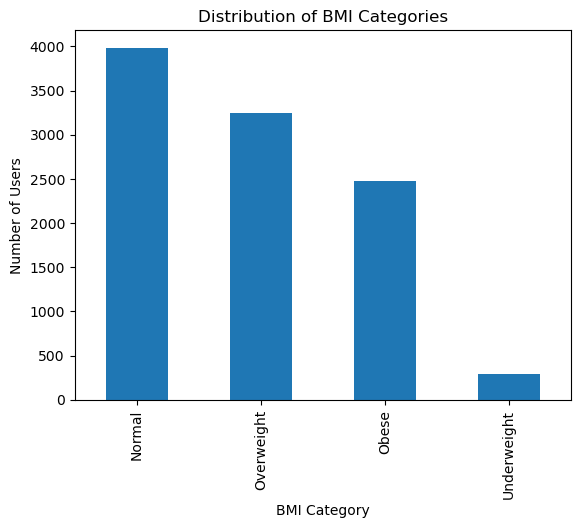

In [22]:
# visualization
df['BMI_Category'].value_counts().plot(
    kind='bar',
    title='Distribution of BMI Categories',
    xlabel='BMI Category',
    ylabel='Number of Users'
)

plt.show()

 the BMI feature was selected for binning because it can be divided into meaningful ranges. Four categories were created: Underweight, Normal, Overweight, and Obese.

In [23]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Columns that should not be considered for binning
excluded_columns = (
    binary_columns +
    ordinal_columns +
    ['User_ID', 'BMI']
)

# Exclude one-hot encoded columns
excluded_columns += [
    col for col in df.columns
    if any(col.startswith(prefix + '_') for prefix in nominal_columns)
]

# Select remaining numerical columns
candidate_columns = [
    col for col in numerical_columns
    if col not in excluded_columns
]

print("Potential columns for binning:")
print(candidate_columns)

Potential columns for binning:
['Age', 'Height_cm', 'Weight_kg', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Heart_Rate', 'Body_Fat_Percent', 'Reward_Points', 'Streak_Days']


In [24]:
binning_analysis = pd.DataFrame({
    'Unique Values': df[candidate_columns].nunique(),
    'Minimum': df[candidate_columns].min(),
    'Maximum': df[candidate_columns].max(),
    'Mean': df[candidate_columns].mean(),
    'Median': df[candidate_columns].median(),
    'Skewness': df[candidate_columns].skew()
})

display(binning_analysis)

,Unique Values,Minimum,Maximum,Mean,Median,Skewness
Age,13,18.0,30.0,23.94110,24.0,0.030796
Height_cm,401,150.0,190.0,170.00957,169.9,0.005545
Weight_kg,784,40.8,122.4,75.50819,74.0,0.315139
Daily_Steps,7214,2001.0,18000.0,8602.56850,7912.0,0.463686
Workout_Days,8,0.0,7.0,3.64300,4.0,-0.176543
Workout_Duration_Min,71,20.0,90.0,54.87300,55.0,0.008591
Calories_Burned,1104,325.0,1546.0,878.33000,869.0,0.211808
Sleep_Hours,36,5.5,9.0,7.25723,7.3,-0.009707
Stress_Level,10,1.0,10.0,5.52900,6.0,-0.017798
Water_Intake_L,36,1.5,5.0,2.97312,2.9,0.245299


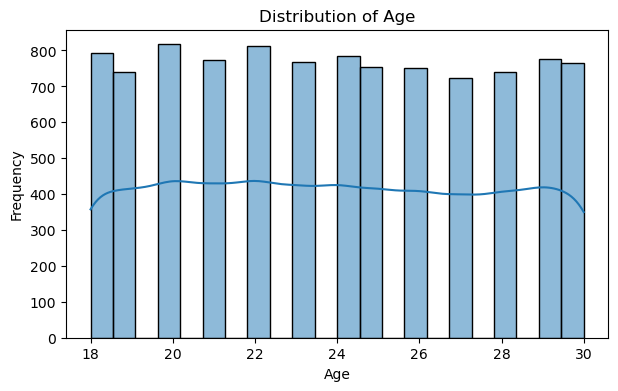

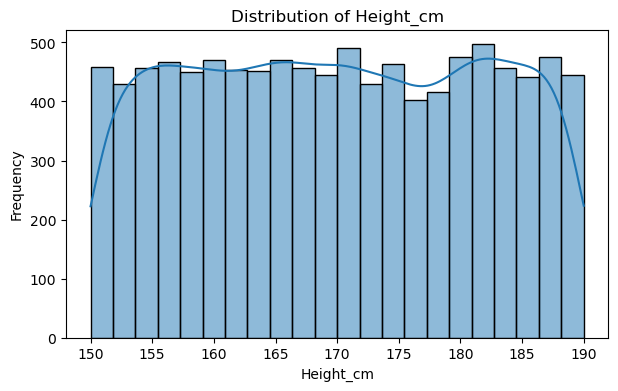

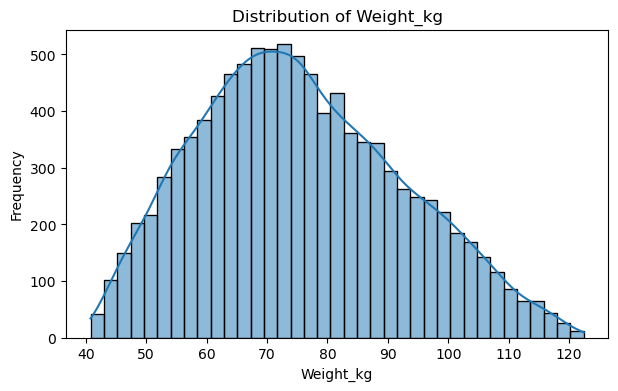

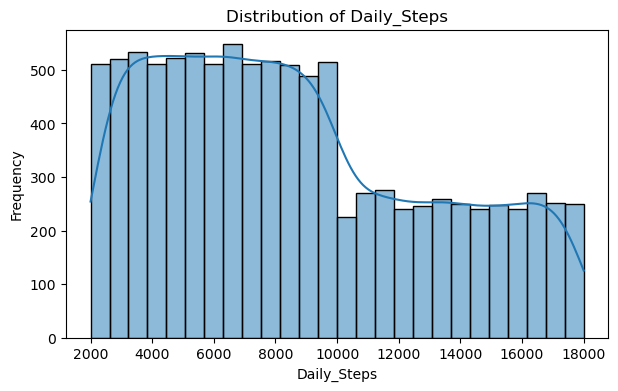

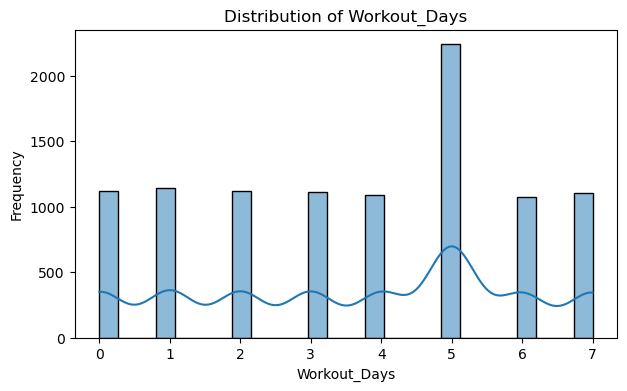

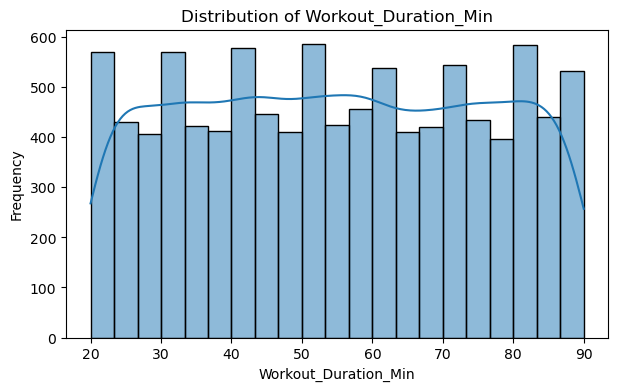

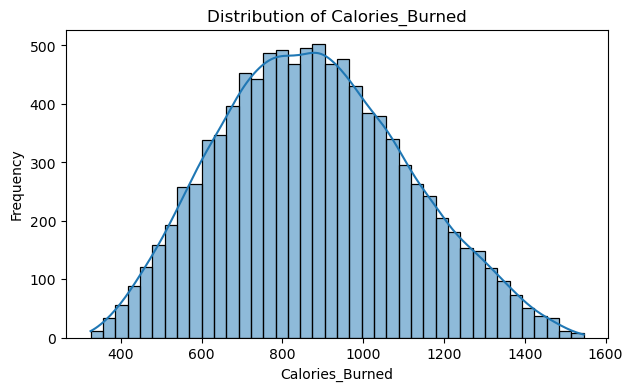

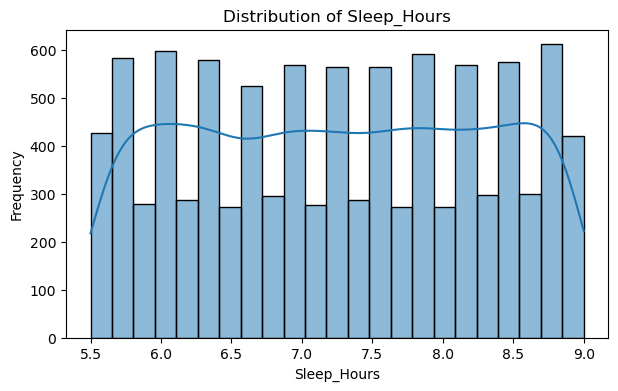

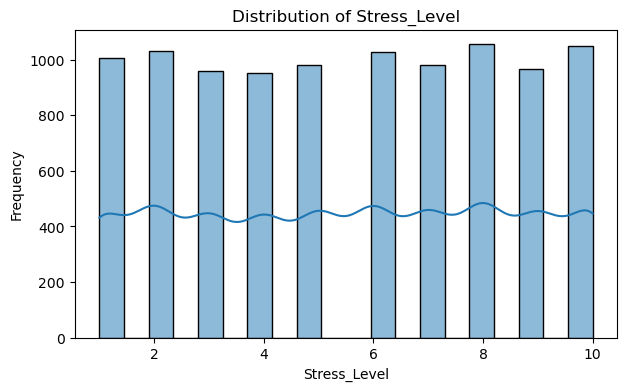

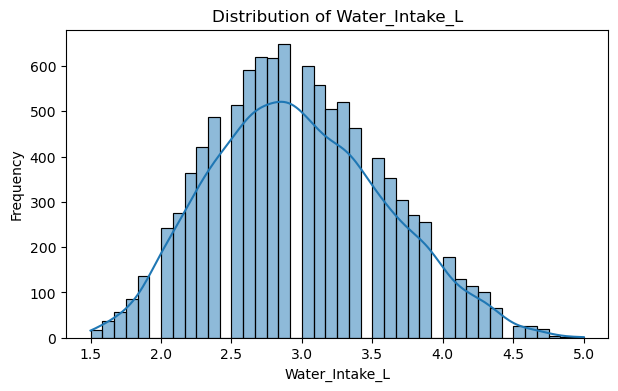

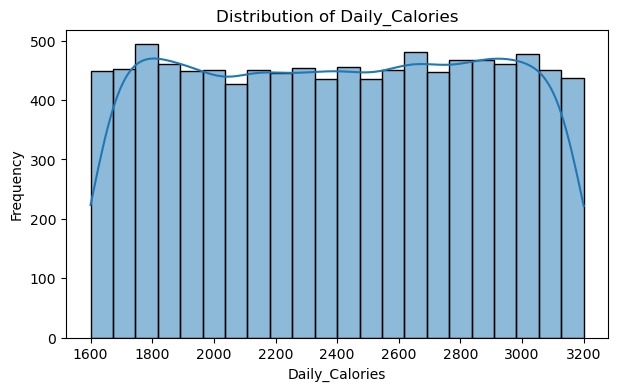

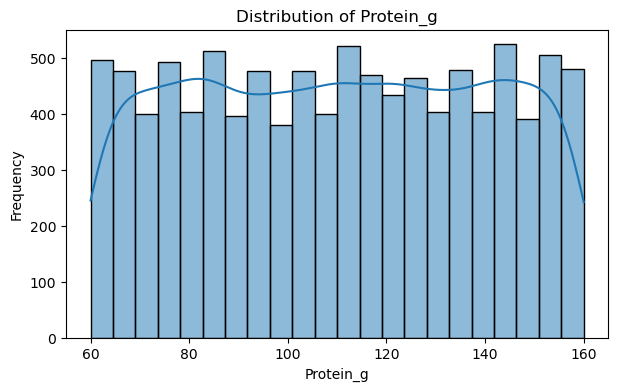

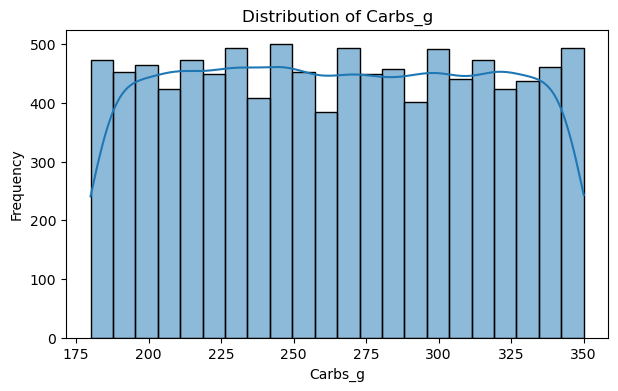

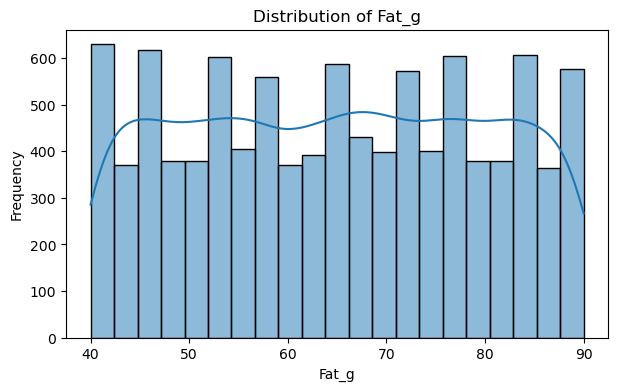

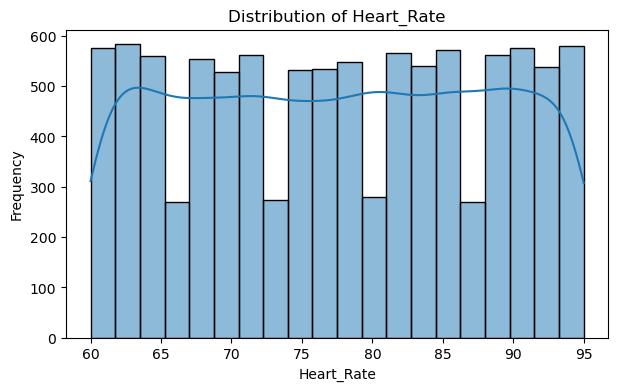

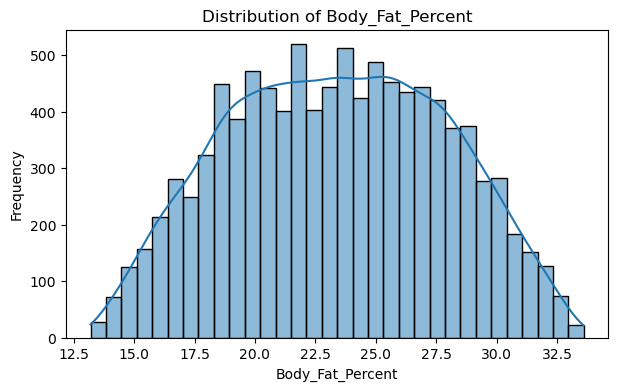

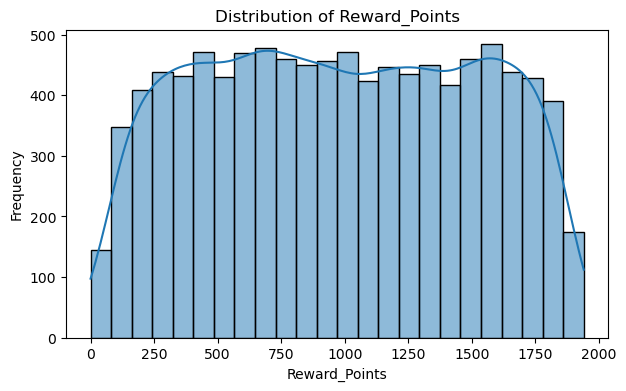

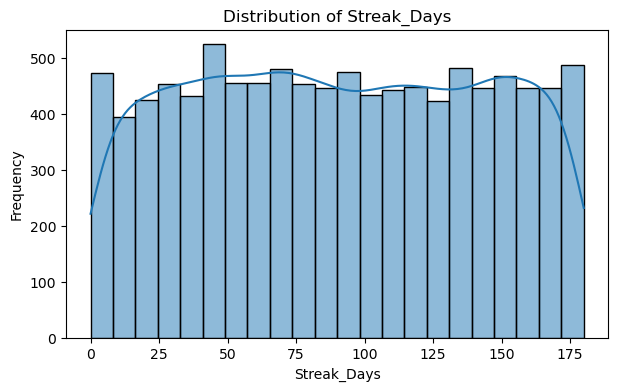

In [25]:
for column in candidate_columns:
    plt.figure(figsize=(7, 4))

    sns.histplot(df[column], kde=True)

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

    plt.show()

In [26]:
# Define age bins
age_bins = [17, 21, 25, float('inf')]

# Define labels
age_labels = [
    'Young',
    'Early Adult',
    'Adult'
]

# Apply binning
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=age_bins,
    labels=age_labels
)

print(df[['Age', 'Age_Group']].head(10))

   Age    Age_Group
0   28        Adult
1   30        Adult
2   27        Adult
3   25  Early Adult
4   21        Young
5   18        Young
6   23  Early Adult
7   20        Young
8   21        Young
9   28        Adult


In [27]:
# Define daily steps bins
step_bins = [0, 5000, 7500, 10000, float('inf')]

# Define labels
step_labels = [
    'Low',
    'Moderate',
    'Active',
    'Highly Active'
]

# Apply binning
df['Daily_Steps_Category'] = pd.cut(
    df['Daily_Steps'],
    bins=step_bins,
    labels=step_labels,
    right=False
)

print(df[['Daily_Steps', 'Daily_Steps_Category']].head(10))

   Daily_Steps Daily_Steps_Category
0         5016             Moderate
1         5920             Moderate
2        12370        Highly Active
3        12656        Highly Active
4         6898             Moderate
5        12404        Highly Active
6         4453                  Low
7        15651        Highly Active
8         5708             Moderate
9         4758                  Low


In [28]:
# Check BMI categories
print("BMI Categories:")
print(df['BMI_Category'].value_counts())

# Check Age groups
print("\nAge Groups:")
print(df['Age_Group'].value_counts())

# Check Daily Steps categories
print("\nDaily Steps Categories:")
print(df['Daily_Steps_Category'].value_counts())

BMI Categories:
BMI_Category
Normal         3985
Overweight     3242
Obese          2479
Underweight     294
Name: count, dtype: int64

Age Groups:
Age_Group
Adult          3755
Young          3124
Early Adult    3121
Name: count, dtype: int64

Daily Steps Categories:
Daily_Steps_Category
Highly Active    3270
Low              2530
Moderate         2134
Active           2066
Name: count, dtype: int64


Binning is a discretization technique used to convert continuous numerical values into discrete intervals or categories.

In the CampusFit dataset, three features were selected for binning:

BMI: Divided into Underweight, Normal, Overweight, and Obese categories using predefined BMI boundaries.

Age: Divided into Young (18–21), Early Adult (22–25), and Adult (26–30) groups.

Daily_Steps: Divided into Low, Moderate, Active, and Highly Active activity ranges.

The Pandas pd.cut() function was used to create these categories.

The original numerical columns were retained, and new categorical columns were created to preserve the original information.

In [29]:
print("Original Dataset Shape:", df.shape)

print("\nNewly Created Binned Columns:")
display(df[
    ['BMI', 'BMI_Category',
     'Age', 'Age_Group',
     'Daily_Steps', 'Daily_Steps_Category']
].head(10))

Original Dataset Shape: (10000, 41)

Newly Created Binned Columns:


,BMI,BMI_Category,Age,Age_Group,Daily_Steps,Daily_Steps_Category
0,22.4,Normal,28,Adult,5016,Moderate
1,23.4,Normal,30,Adult,5920,Moderate
2,29.3,Overweight,27,Adult,12370,Highly Active
3,32.8,Obese,25,Early Adult,12656,Highly Active
4,24.9,Normal,21,Young,6898,Moderate
5,26.6,Overweight,18,Young,12404,Highly Active
6,30.5,Obese,23,Early Adult,4453,Low
7,27.7,Overweight,20,Young,15651,Highly Active
8,28.1,Overweight,21,Young,5708,Moderate
9,24.6,Normal,28,Adult,4758,Low


Selected BMI, Age and Daily_Steps for binning because their numerical values can be converted into meaningful categories that make user segmentation and behavioural analysis easier. Avoided binning the remaining numerical features because their exact values contain useful information, and unnecessary binning could lead to information loss.

In [30]:
# Scaling 
scaling_columns = [
    'Age',
    'Height_cm',
    'Weight_kg',
    'BMI',
    'Daily_Steps',
    'Workout_Days',
    'Workout_Duration_Min',
    'Calories_Burned',
    'Sleep_Hours',
    'Stress_Level',
    'Water_Intake_L',
    'Daily_Calories',
    'Protein_g',
    'Carbs_g',
    'Fat_g',
    'Heart_Rate',
    'Body_Fat_Percent',
    'Reward_Points',
    'Streak_Days'
]

print("Columns selected for scaling:")
print(scaling_columns)

print("\nTotal columns selected:", len(scaling_columns))

Columns selected for scaling:
['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Heart_Rate', 'Body_Fat_Percent', 'Reward_Points', 'Streak_Days']

Total columns selected: 19


In [31]:
# Check whether all selected columns exist in the dataset
missing_columns = [
    col for col in scaling_columns
    if col not in df.columns
]

print("Missing columns:", missing_columns)

# Check data types
print("\nData types:")
print(df[scaling_columns].dtypes)

# Check missing values
print("\nMissing values:")
print(df[scaling_columns].isnull().sum().sum())

Missing columns: []

Data types:
Age                       int64
Height_cm               float64
Weight_kg               float64
BMI                     float64
Daily_Steps               int64
Workout_Days              int64
Workout_Duration_Min      int64
Calories_Burned           int64
Sleep_Hours             float64
Stress_Level              int64
Water_Intake_L          float64
Daily_Calories            int64
Protein_g                 int64
Carbs_g                   int64
Fat_g                     int64
Heart_Rate                int64
Body_Fat_Percent        float64
Reward_Points             int64
Streak_Days               int64
dtype: object

Missing values:
0


In [32]:
# Select numerical columns for outlier detection
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove User_ID if present
numerical_columns = [
    col for col in numerical_columns
    if col != 'User_ID'
]

print("Numerical columns selected:")
print(numerical_columns)

print("\nTotal numerical columns:", len(numerical_columns))

Numerical columns selected:
['Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Activity_Level', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Diet_Type', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Mood', 'Heart_Rate', 'Body_Fat_Percent', 'Fitness_Level', 'Hydration_Status', 'Reward_Points', 'Streak_Days', 'Dropout_Risk', 'Fitness_Goal_Muscle Gain', 'Fitness_Goal_Stay Fit', 'Fitness_Goal_Weight Loss', 'Workout_Type_Cardio', 'Workout_Type_HIIT', 'Workout_Type_Mixed', 'Workout_Type_Strength', 'Workout_Type_Yoga', 'Recommended_Diet_Balanced', 'Recommended_Diet_Calorie Deficit', 'Recommended_Diet_High Protein']

Total numerical columns: 37


In [33]:
# Select original numerical measurement columns
numerical_columns = scaling_columns.copy()

print("Numerical columns selected for outlier detection:")
print(numerical_columns)

print("\nTotal numerical columns:", len(numerical_columns))


Numerical columns selected for outlier detection:
['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Heart_Rate', 'Body_Fat_Percent', 'Reward_Points', 'Streak_Days']

Total numerical columns: 19


In [34]:
import pandas as pd

# Create an empty list to store outlier results
outlier_results = []

# Calculate IQR for each numerical column
for column in numerical_columns:

    # Calculate first and third quartiles
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate Interquartile Range
    IQR = Q3 - Q1

    # Calculate lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify potential outliers
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    # Store results
    outlier_results.append({
        'Column': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (len(outliers) / len(df)) * 100
    })

# Convert results into a DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Display results
outlier_summary


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,21.00,27.0,6.00,12.000,36.000,0,0.00
1,Height_cm,160.00,180.3,20.30,129.550,210.750,0,0.00
2,Weight_kg,62.90,87.3,24.40,26.300,123.900,0,0.00
3,BMI,22.10,29.9,7.80,10.400,41.600,0,0.00
4,Daily_Steps,4965.25,11838.0,6872.75,-5343.875,22147.125,0,0.00
5,Workout_Days,2.00,5.0,3.00,-2.500,9.500,0,0.00
6,Workout_Duration_Min,37.00,73.0,36.00,-17.000,127.000,0,0.00
7,Calories_Burned,707.00,1040.0,333.00,207.500,1539.500,2,0.02
8,Sleep_Hours,6.40,8.1,1.70,3.850,10.650,0,0.00
9,Stress_Level,3.00,8.0,5.00,-4.500,15.500,0,0.00


In [35]:
# Columns where potential outliers were detected
outlier_columns = ['Calories_Burned', 'Water_Intake_L']

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Extract potential outlier values
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ][column]

    print(f"\nColumn: {column}")
    print("Potential outlier values:")
    print(outliers.tolist())
    


Column: Calories_Burned
Potential outlier values:
[1546, 1542]

Column: Water_Intake_L
Potential outlier values:
[4.9, 4.9, 4.8, 4.8, 4.8, 5.0, 4.8]


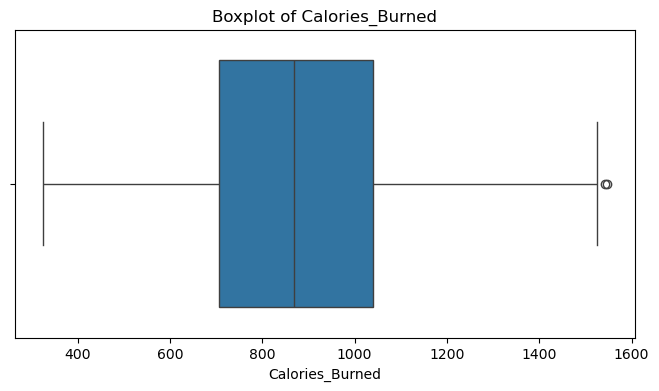

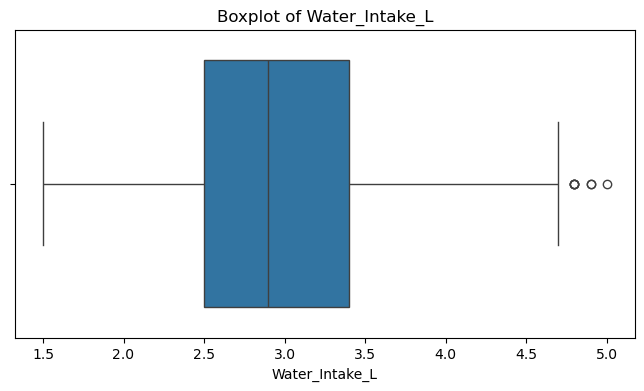

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

for column in outlier_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)

    plt.show()

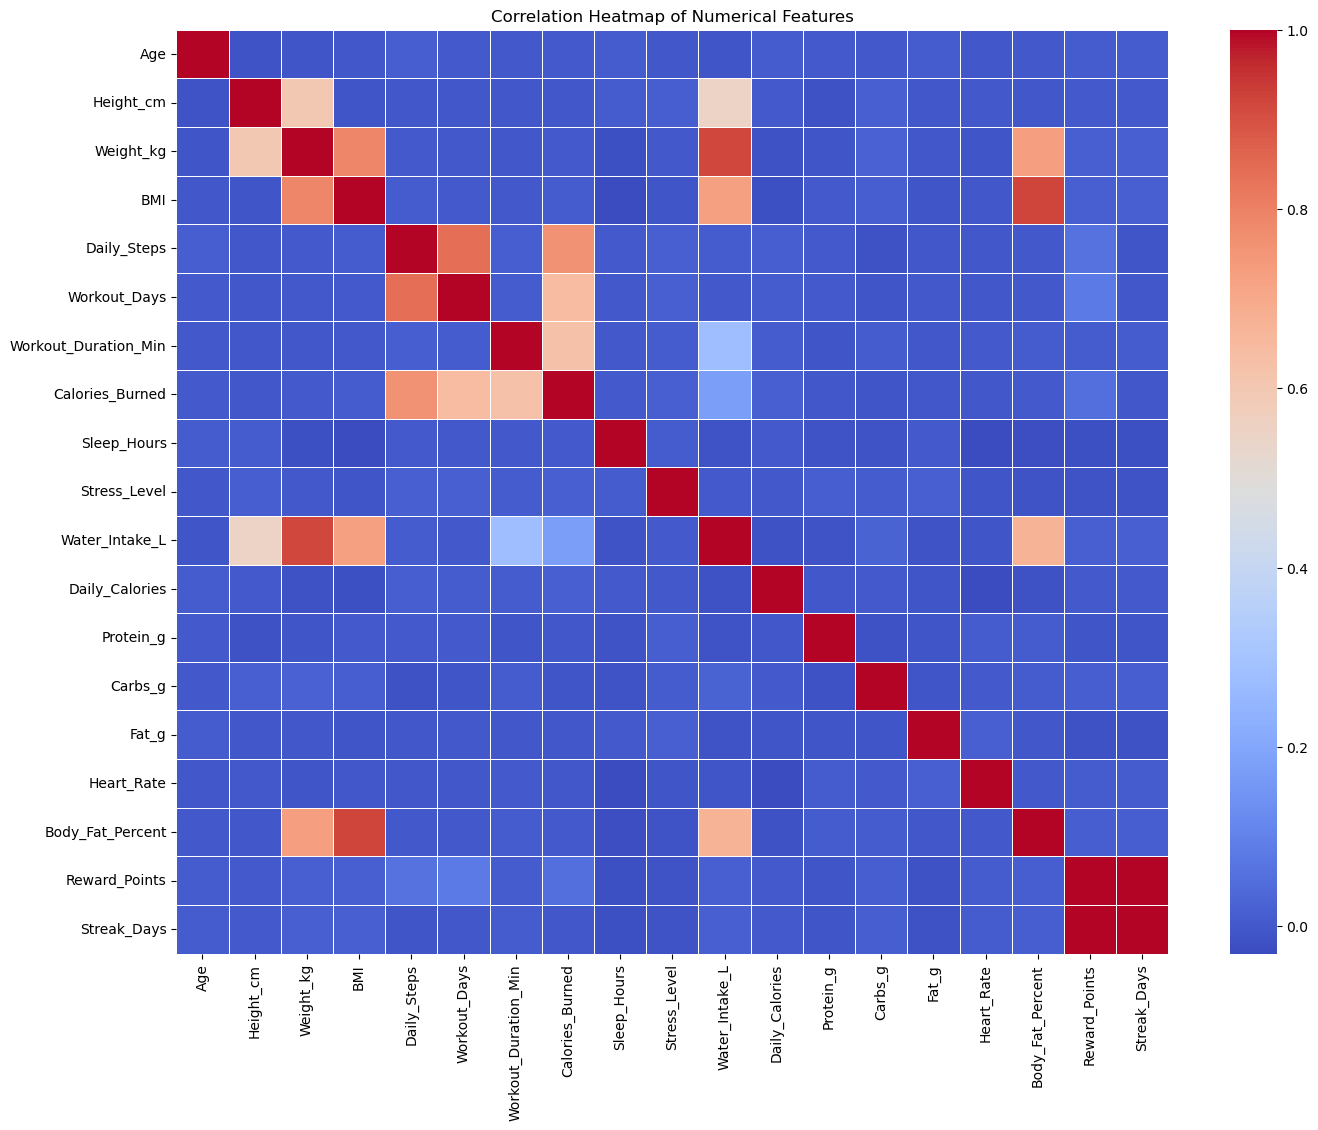

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between numerical features
correlation_matrix = df[numerical_columns].corr()

# Display correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [38]:
# Get the upper triangle of the correlation matrix
import numpy as np

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find highly correlated feature pairs
highly_correlated = [
    (column, row, upper_triangle.loc[row, column])
    for column in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, column])
    and abs(upper_triangle.loc[row, column]) > 0.80
]

# Display results
print("Highly correlated feature pairs:")

for feature1, feature2, correlation in highly_correlated:
    print(f"{feature1} - {feature2}: {correlation:.3f}")

print("\nTotal highly correlated pairs:", len(highly_correlated))

Highly correlated feature pairs:
Workout_Days - Daily_Steps: 0.841
Water_Intake_L - Weight_kg: 0.918
Body_Fat_Percent - BMI: 0.922
Streak_Days - Reward_Points: 0.996

Total highly correlated pairs: 4


In [39]:
# Check descriptive statistics of highly correlated columns

correlated_columns = [
    'Streak_Days',
    'Reward_Points',
    'Body_Fat_Percent',
    'BMI',
    'Water_Intake_L',
    'Weight_kg',
    'Workout_Days',
    'Daily_Steps'
]

print(df[correlated_columns].describe())

       Streak_Days  Reward_Points  Body_Fat_Percent           BMI  \
count  10000.00000   10000.000000      10000.000000  10000.000000   
mean      90.38860     976.746000         23.391210     26.008960   
std       51.85187     520.187361          4.474295      4.599663   
min        0.00000       0.000000         13.200000     18.000000   
25%       46.00000     530.000000         19.900000     22.100000   
50%       90.00000     970.000000         23.400000     26.000000   
75%      135.00000    1430.000000         26.900000     29.900000   
max      180.00000    1940.000000         33.600000     34.000000   

       Water_Intake_L     Weight_kg  Workout_Days  Daily_Steps  
count    10000.000000  10000.000000  10000.000000  10000.00000  
mean         2.973120     75.508190      3.643000   8602.56850  
std          0.614398     16.850953      2.213513   4406.37234  
min          1.500000     40.800000      0.000000   2001.00000  
25%          2.500000     62.900000      2.000000   4

In [40]:
# Check whether Reward_Points is almost a linear multiple of Streak_Days

print(
    df[['Streak_Days', 'Reward_Points']].head(10)
)

   Streak_Days  Reward_Points
0          150           1540
1           20            200
2          136           1460
3           36            460
4          135           1430
5          155           1670
6          168           1680
7          141           1530
8           48            500
9           19            190


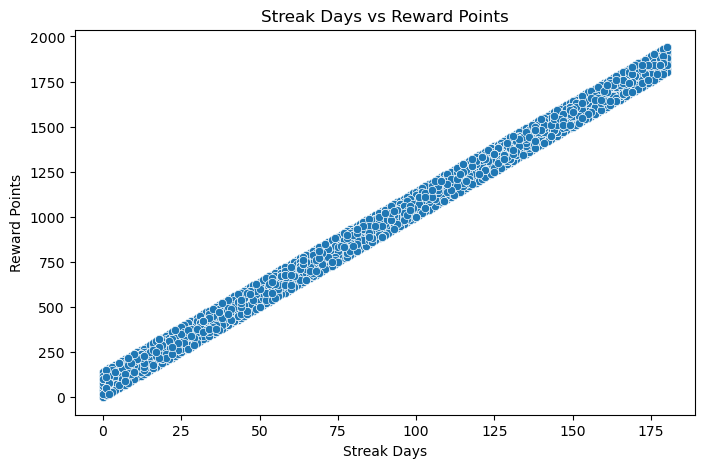

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Streak_Days',
    y='Reward_Points'
)

plt.title('Streak Days vs Reward Points')
plt.xlabel('Streak Days')
plt.ylabel('Reward Points')

plt.show()

In [42]:
# Compare average feature values across dropout risk categories

print("Average Streak Days by Dropout Risk:")
print(df.groupby('Dropout_Risk')['Streak_Days'].mean())

print("\nAverage Reward Points by Dropout Risk:")
print(df.groupby('Dropout_Risk')['Reward_Points'].mean())

Average Streak Days by Dropout Risk:
Dropout_Risk
0    99.686476
1    10.156118
2     2.048193
Name: Streak_Days, dtype: float64

Average Reward Points by Dropout Risk:
Dropout_Risk
0    1069.559594
1     175.379747
2     100.240964
Name: Reward_Points, dtype: float64


In [43]:
# Calculate Spearman correlation with Dropout_Risk

streak_corr = df['Streak_Days'].corr(
    df['Dropout_Risk'],
    method='spearman'
)

reward_corr = df['Reward_Points'].corr(
    df['Dropout_Risk'],
    method='spearman'
)

print("Streak_Days vs Dropout_Risk:", round(streak_corr, 4))

print("Reward_Points vs Dropout_Risk:", round(reward_corr, 4))

Streak_Days vs Dropout_Risk: -0.5269
Reward_Points vs Dropout_Risk: -0.5235


We identified four highly correlated feature pairs using a correlation threshold of 0.80. Among these, Streak_Days and Reward_Points showed an exceptionally high correlation of 0.996. Their Spearman correlations with Dropout_Risk were also nearly identical (-0.5269 and -0.5235). Therefore, Streak_Days was selected for retention because it directly represents workout consistency, while Reward_Points was identified as a candidate for removal to reduce redundant information.

PCA is a feature-extraction technique that transforms original numerical features into new components while preserving as much variance as possible.

For our project, we will not apply PCA at this stage because:
1. We have identified a candidate for feature selection.
2. Keeping original features makes the model easier to interpret.
3. PCA creates new components that are less directly interpretable.
4. We have not established that PCA would improve our model.
PCA was evaluated as an alternative dimensionality-reduction technique. However, it was not selected for the current preprocessing approach because retaining the original features provides better interpretability for analysing fitness behaviour and dropout risk.

## Model Training

In [44]:
# Define the target column
target_column = 'Dropout_Risk'

# Separate input features (X) and target (y)
X = df.drop(columns=[target_column])
y = df[target_column]

# Display shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display target distribution
print("\nTarget distribution:")
print(y.value_counts().sort_index())

# Display target data type
print("\nTarget data type:", y.dtype)

Features shape: (10000, 40)
Target shape: (10000,)

Target distribution:
Dropout_Risk
0    8969
1     948
2      83
Name: count, dtype: int64

Target data type: int64


In [45]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(
    columns=['Dropout_Risk', 'User_ID', 'Reward_Points'],
    errors='ignore'
)

y = df['Dropout_Risk']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (8000, 38)
Testing features: (2000, 38)

Training target distribution:
Dropout_Risk
0    7175
1     758
2      67
Name: count, dtype: int64

Testing target distribution:
Dropout_Risk
0    1794
1     190
2      16
Name: count, dtype: int64


In [46]:
print("Missing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

Missing values in training data:
0

Missing values in testing data:
0


In [47]:
from sklearn.preprocessing import StandardScaler

In [48]:
numerical_columns = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("\nTotal numerical columns:", len(numerical_columns))

Numerical columns: ['Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Activity_Level', 'Daily_Steps', 'Workout_Days', 'Workout_Duration_Min', 'Calories_Burned', 'Sleep_Hours', 'Stress_Level', 'Water_Intake_L', 'Diet_Type', 'Daily_Calories', 'Protein_g', 'Carbs_g', 'Fat_g', 'Mood', 'Heart_Rate', 'Body_Fat_Percent', 'Fitness_Level', 'Hydration_Status', 'Streak_Days', 'Fitness_Goal_Muscle Gain', 'Fitness_Goal_Stay Fit', 'Fitness_Goal_Weight Loss', 'Workout_Type_Cardio', 'Workout_Type_HIIT', 'Workout_Type_Mixed', 'Workout_Type_Strength', 'Workout_Type_Yoga', 'Recommended_Diet_Balanced', 'Recommended_Diet_Calorie Deficit', 'Recommended_Diet_High Protein']

Total numerical columns: 35


In [49]:
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = X_train.copy()
X_train_scaled[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

# Transform testing data using the same scaler
X_test_scaled = X_test.copy()
X_test_scaled[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

In [50]:
print("Training data after scaling:")
print(X_train_scaled[numerical_columns].describe().round(2))

Training data after scaling:
           Age  Gender  Height_cm  Weight_kg      BMI  Activity_Level  \
count  8000.00  8000.0    8000.00    8000.00  8000.00         8000.00   
mean      0.00     0.0      -0.00       0.00    -0.00            0.00   
std       1.00     1.0       1.00       1.00     1.00            1.00   
min      -1.58    -1.0      -1.73      -2.06    -1.75           -1.20   
25%      -0.78    -1.0      -0.87      -0.75    -0.85           -1.20   
50%       0.02     1.0      -0.01      -0.10    -0.00            0.02   
75%       0.82     1.0       0.89       0.70     0.85            1.24   
max       1.62     1.0       1.73       2.73     1.75            1.24   

       Daily_Steps  Workout_Days  Workout_Duration_Min  Calories_Burned  ...  \
count      8000.00       8000.00               8000.00          8000.00  ...   
mean         -0.00         -0.00                  0.00            -0.00  ...   
std           1.00          1.00                  1.00             1.00  

In [51]:
print("Mean of scaled features:")
print(X_train_scaled[numerical_columns].mean().round(2))

print("\nStandard deviation of scaled features:")
print(X_train_scaled[numerical_columns].std().round(2))

Mean of scaled features:
Age                                 0.0
Gender                              0.0
Height_cm                          -0.0
Weight_kg                           0.0
BMI                                -0.0
Activity_Level                      0.0
Daily_Steps                        -0.0
Workout_Days                       -0.0
Workout_Duration_Min                0.0
Calories_Burned                    -0.0
Sleep_Hours                         0.0
Stress_Level                       -0.0
Water_Intake_L                     -0.0
Diet_Type                          -0.0
Daily_Calories                     -0.0
Protein_g                           0.0
Carbs_g                            -0.0
Fat_g                              -0.0
Mood                                0.0
Heart_Rate                          0.0
Body_Fat_Percent                   -0.0
Fitness_Level                       0.0
Hydration_Status                    0.0
Streak_Days                        -0.0
Fitness_Goal_Mu

In [52]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

In [53]:
categorical_columns = X_train_scaled.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical columns:", categorical_columns)

Categorical columns: ['BMI_Category', 'Age_Group', 'Daily_Steps_Category']


In [54]:
from sklearn.preprocessing import OrdinalEncoder

In [55]:
category_orders = [
    ['Underweight', 'Normal', 'Overweight', 'Obese'],
    ['Young', 'Early Adult', 'Adult'],
    ['Low', 'Moderate', 'Active', 'Highly Active']
]

categorical_columns = [
    'BMI_Category',
    'Age_Group',
    'Daily_Steps_Category'
]

In [56]:
ordinal_encoder = OrdinalEncoder(
    categories=category_orders,
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_scaled[categorical_columns] = ordinal_encoder.fit_transform(
    X_train_scaled[categorical_columns]
)

X_test_scaled[categorical_columns] = ordinal_encoder.transform(
    X_test_scaled[categorical_columns]
)

In [57]:
print("Remaining categorical columns:")
print(
    X_train_scaled.select_dtypes(
        include=['object', 'category']
    ).columns.tolist()
)

print("\nData types:")
print(X_train_scaled.dtypes.value_counts())

Remaining categorical columns:
[]

Data types:
float64    38
Name: count, dtype: int64


In [116]:
# Feature Selection using SelectKBest

from sklearn.feature_selection import SelectKBest, f_classif

# Select the top 10 important features
selector = SelectKBest(score_func=f_classif, k=10)

# Fit feature selector using training data only
X_train_selected = selector.fit_transform(
    X_train_scaled,
    y_train
)

# Apply the same selection to testing data
X_test_selected = selector.transform(X_test_scaled)

# Get selected feature names
selected_features = X_train_scaled.columns[selector.get_support()]

# Display selected features and their scores
feature_scores = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'F_Score': selector.scores_
})

feature_scores = feature_scores.sort_values(
    by='F_Score',
    ascending=False
)

print("Features before selection:", X_train_scaled.shape[1])
print("Features after selection:", len(selected_features))

print("\nSelected Features:")
print(selected_features.tolist())

print("\nFeature Scores:")
display(feature_scores.head(10).round(4))

Features before selection: 38
Features after selection: 10

Selected Features:
['Gender', 'Height_cm', 'Weight_kg', 'Stress_Level', 'Diet_Type', 'Carbs_g', 'Mood', 'Streak_Days', 'Fitness_Goal_Muscle Gain', 'Recommended_Diet_High Protein']

Feature Scores:


,Feature,F_Score
23,Streak_Days,1557.8123
11,Stress_Level,47.0680
18,Mood,27.7201
34,Recommended_Diet_High Protein,3.2081
24,Fitness_Goal_Muscle Gain,3.2081
16,Carbs_g,3.0295
2,Height_cm,2.2631
1,Gender,1.8362
3,Weight_kg,1.5974
13,Diet_Type,1.5169


# Train the Decision Tree Classifier

In [59]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

In [118]:
dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [61]:
y_pred = dt_model.predict(X_test_scaled)

print("First 15 predicted values:")
print(y_pred[:15])

print("\nFirst 15 actual values:")
print(y_test.iloc[:15].values)

First 15 predicted values:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]

First 15 actual values:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]


## Calculate evaluation Metrics

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

print("Decision Tree Evaluation")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Decision Tree Evaluation
------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


In [63]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=['Low Risk', 'Medium Risk', 'High Risk'],
    zero_division=0
))

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00      1794
 Medium Risk       1.00      1.00      1.00       190
   High Risk       1.00      1.00      1.00        16

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



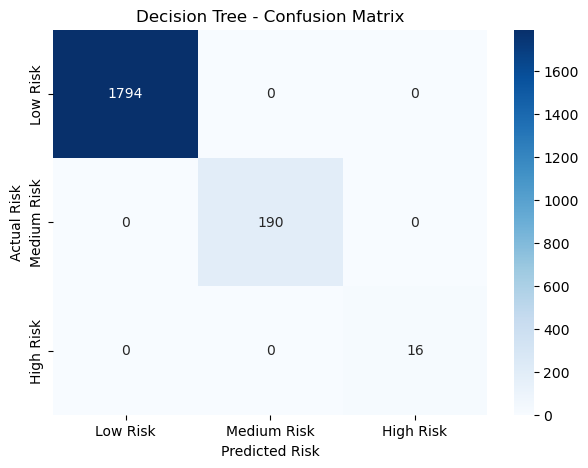

In [64]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Risk', 'Medium Risk', 'High Risk'],
    yticklabels=['Low Risk', 'Medium Risk', 'High Risk']
)

plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

In [120]:
import pandas as pd

feature_importance = pd.DataFrame({
    
    'Importance': dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

      Importance
23  8.422222e-01
11  1.577778e-01
33  3.207434e-13
9   3.969853e-15
0   0.000000e+00
22  0.000000e+00
24  0.000000e+00
25  0.000000e+00
26  0.000000e+00
27  0.000000e+00
28  0.000000e+00
29  0.000000e+00
20  0.000000e+00
30  0.000000e+00
31  0.000000e+00
32  0.000000e+00
34  0.000000e+00
35  0.000000e+00
36  0.000000e+00
21  0.000000e+00
19  0.000000e+00
1   0.000000e+00
8   0.000000e+00
2   0.000000e+00
3   0.000000e+00
4   0.000000e+00
5   0.000000e+00
6   0.000000e+00
7   0.000000e+00
10  0.000000e+00
18  0.000000e+00
12  0.000000e+00
13  0.000000e+00
14  0.000000e+00
15  0.000000e+00
16  0.000000e+00
17  0.000000e+00
37  0.000000e+00


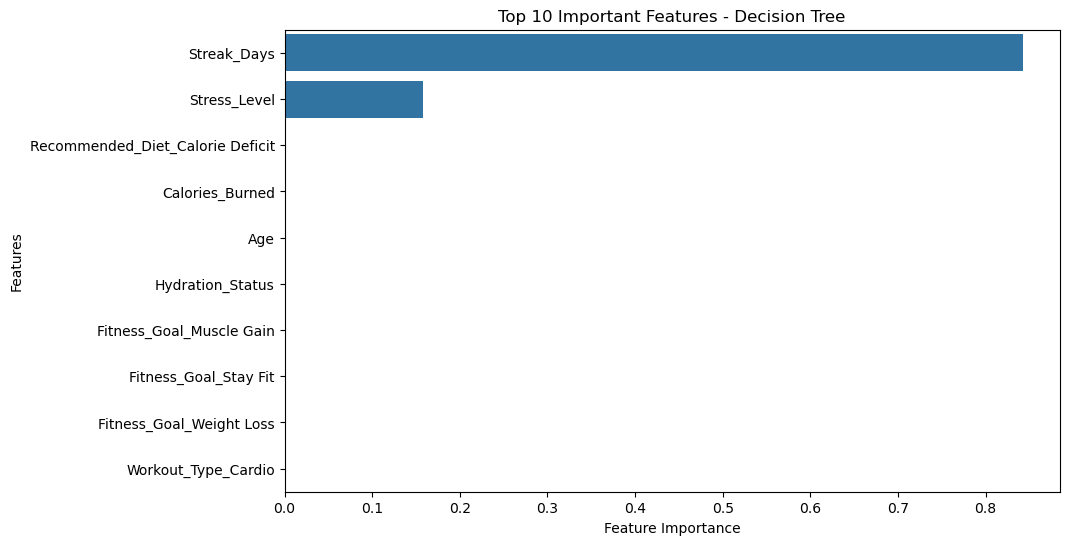

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Decision Tree')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

The Decision Tree feature importance analysis identified Streak_Days as the most influential feature in predicting dropout risk, followed by Stress_Level. The remaining features had negligible importance in this model. This suggests that workout consistency and stress levels are important predictive indicators in the CampusFit dataset. However, feature importance indicates predictive contribution, not causation.

## Random Forest Classifier

In [67]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

rf_pred = rf_model.predict(X_test_scaled)

Random Forest model trained successfully!


In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(
    y_test, rf_pred, average='weighted', zero_division=0
)

rf_recall = recall_score(
    y_test, rf_pred, average='weighted', zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_pred, average='weighted', zero_division=0
)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-Score:", round(rf_f1, 4))

Random Forest Evaluation
------------------------
Accuracy: 0.9985
Precision: 0.9985
Recall: 0.9985
F1-Score: 0.9984


In [69]:
print(classification_report(
    y_test,
    rf_pred,
    labels=[0, 1, 2],
    target_names=['Low Risk', 'Medium Risk', 'High Risk'],
    zero_division=0
))

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00      1794
 Medium Risk       0.98      1.00      0.99       190
   High Risk       1.00      0.81      0.90        16

    accuracy                           1.00      2000
   macro avg       0.99      0.94      0.96      2000
weighted avg       1.00      1.00      1.00      2000



## Decision Tree VS Random Forest 

In [70]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Decision Tree': [
        accuracy,
        precision,
        recall,
        f1
    ],
    'Random Forest': [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print(model_comparison.round(4))

      Metric  Decision Tree  Random Forest
0   Accuracy            1.0         0.9985
1  Precision            1.0         0.9985
2     Recall            1.0         0.9985
3   F1-Score            1.0         0.9984


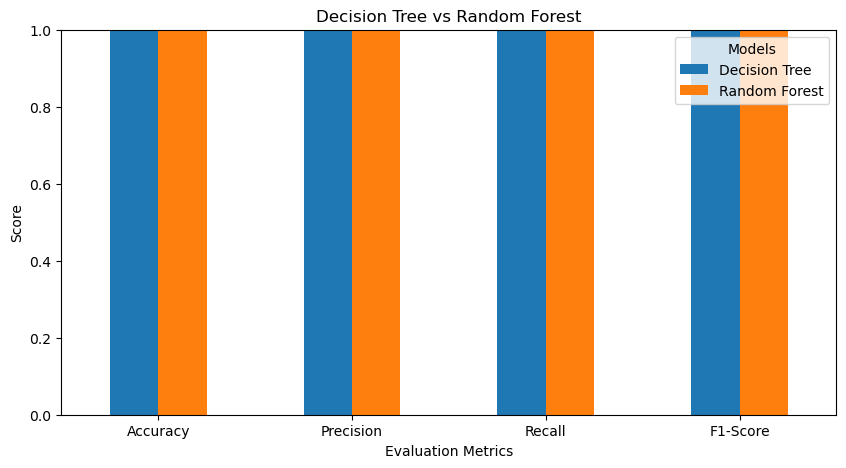

In [71]:
model_comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title('Decision Tree vs Random Forest')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.xticks(rotation=0)
plt.legend(title='Models')
plt.show()

In [72]:
from sklearn.metrics import f1_score

dt_macro_f1 = f1_score(
    y_test, y_pred, average='macro', zero_division=0
)

rf_macro_f1 = f1_score(
    y_test, rf_pred, average='macro', zero_division=0
)

print("Decision Tree Macro F1:", round(dt_macro_f1, 4))
print("Random Forest Macro F1:", round(rf_macro_f1, 4))

Decision Tree Macro F1: 1.0
Random Forest Macro F1: 0.9629


In [73]:
# Examine Streak_Days for each dropout-risk category

streak_analysis = df.groupby('Dropout_Risk')['Streak_Days'].agg(
    ['count', 'min', 'max', 'mean', 'median']
)

print(streak_analysis)

              count  min  max       mean  median
Dropout_Risk                                    
0              8969   20  180  99.686476    99.0
1               948    0   19  10.156118    10.0
2                83    0    4   2.048193     2.0


In [74]:
# Check the distribution of dropout risk across streak ranges

streak_bins = [-1, 2, 10, 30, 60, 180, float('inf')]

streak_labels = [
    '0-2 days',
    '3-10 days',
    '11-30 days',
    '31-60 days',
    '61-180 days',
    'Above 180'
]

df['Streak_Group'] = pd.cut(
    df['Streak_Days'],
    bins=streak_bins,
    labels=streak_labels
)

print(pd.crosstab(
    df['Streak_Group'],
    df['Dropout_Risk'],
    normalize='index'
).round(3))

Dropout_Risk     0      1      2
Streak_Group                    
0-2 days      0.00  0.671  0.329
3-10 days     0.00  0.919  0.081
11-30 days    0.57  0.430  0.000
31-60 days    1.00  0.000  0.000
61-180 days   1.00  0.000  0.000


In [75]:
print(
    df.groupby('Dropout_Risk')['Streak_Days'].agg(
        ['count', 'min', 'max', 'mean', 'median']
    )
)

              count  min  max       mean  median
Dropout_Risk                                    
0              8969   20  180  99.686476    99.0
1               948    0   19  10.156118    10.0
2                83    0    4   2.048193     2.0


In [76]:
# Training model without Streak_days
# Remove Streak_Days from training and testing features
X_train_no_streak = X_train_scaled.drop(columns=['Streak_Days'])
X_test_no_streak = X_test_scaled.drop(columns=['Streak_Days'])

# Create a new Decision Tree
dt_no_streak = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

# Train and predict
dt_no_streak.fit(X_train_no_streak, y_train)

y_pred_no_streak = dt_no_streak.predict(X_test_no_streak)

# Evaluate using Macro F1
from sklearn.metrics import f1_score

macro_f1_no_streak = f1_score(
    y_test,
    y_pred_no_streak,
    average='macro',
    zero_division=0
)

print("Original Decision Tree Macro F1:", round(dt_macro_f1, 4))
print("Decision Tree without Streak_Days:", round(macro_f1_no_streak, 4))

Original Decision Tree Macro F1: 1.0
Decision Tree without Streak_Days: 0.3337


In [77]:
# Test Case: DroupOut risk rate
# Take one unseen record from the testing dataset
test_case = X_test_scaled.iloc[[0]]

# Predict dropout risk
prediction = dt_model.predict(test_case)

# Convert predicted number into a category
risk_labels = {
    0: "Low Risk",
    1: "Medium Risk",
    2: "High Risk"
}

print("Predicted Dropout Risk:", risk_labels[prediction[0]])
print("Actual Dropout Risk:", risk_labels[y_test.iloc[0]])

Predicted Dropout Risk: Low Risk
Actual Dropout Risk: Low Risk


In [78]:
# Test Case:all three category
for risk in [0, 1, 2]:

    index = y_test[y_test == risk].index[0]

    test_case = X_test_scaled.loc[[index]]

    prediction = dt_model.predict(test_case)[0]

    print("\nActual Risk:", risk_labels[risk])
    print("Predicted Risk:", risk_labels[prediction])


Actual Risk: Low Risk
Predicted Risk: Low Risk

Actual Risk: Medium Risk
Predicted Risk: Medium Risk

Actual Risk: High Risk
Predicted Risk: High Risk


The Decision Tree model was tested using sample records from the test dataset. It correctly predicted all three selected examples belonging to Low Risk, Medium Risk, and High Risk categories. This demonstrates that the model can classify these selected records correctly. Overall model performance was evaluated separately using the Macro F1-score and other classification metrics.

In [84]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
# Load the original dataset
reg_df = pd.read_csv("CampusFit_Synthetic_Dataset_10000.csv")

# Display dataset information
print("Dataset Shape:", reg_df.shape)

# Select target variable
y_reg = reg_df['Calories_Burned']

print("\nTarget Variable: Calories_Burned")
print(y_reg.head())


Dataset Shape: (10000, 30)

Target Variable: Calories_Burned
0     869
1     660
2    1098
3    1147
4     655
Name: Calories_Burned, dtype: int64


## SLR(Predicting Calories Burned using Workout Duration)

In [85]:

# Select one independent variable
X_slr = reg_df[['Workout_Duration_Min']]

# Split dataset into training and testing sets
X_train_slr, X_test_slr, y_train_slr, y_test_slr = train_test_split(
    X_slr,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Create Simple Linear Regression model
slr_model = LinearRegression()

# Train the model
slr_model.fit(X_train_slr, y_train_slr)

# Make predictions
slr_pred = slr_model.predict(X_test_slr)

print("Simple Linear Regression trained successfully!")

# Display model coefficients
print("Intercept:", slr_model.intercept_)
print("Coefficient:", slr_model.coef_[0])


Simple Linear Regression trained successfully!
Intercept: 489.08212164038275
Coefficient: 7.046862670745807


## MLR Predicting Calories Burned using three independent variables('Daily_Steps','Workout_Days','Workout_Duration_Min')

In [86]:

# Select multiple independent variables
X_mlr = reg_df[
    [
        'Daily_Steps',
        'Workout_Days',
        'Workout_Duration_Min'
    ]
]

# Split dataset
X_train_mlr, X_test_mlr, y_train_mlr, y_test_mlr = train_test_split(
    X_mlr,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Create Multiple Linear Regression model
mlr_model = LinearRegression()

# Train the model
mlr_model.fit(X_train_mlr, y_train_mlr)

# Make predictions
mlr_pred = mlr_model.predict(X_test_mlr)

print("Multiple Linear Regression trained successfully!")

# Display coefficients
print("Intercept:", mlr_model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X_mlr.columns,
    'Coefficient': mlr_model.coef_
})

display(coefficients)


Multiple Linear Regression trained successfully!
Intercept: 152.78919917552992


,Feature,Coefficient
0,Daily_Steps,0.039713
1,Workout_Days,0.171474
2,Workout_Duration_Min,6.987296


## PR

In [87]:
# Select independent variables
X_poly = reg_df[
    [
        'Daily_Steps',
        'Workout_Days',
        'Workout_Duration_Min'
    ]
]

# Split dataset
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Create Polynomial Regression model
poly_model = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    LinearRegression()
)

# Train the model
poly_model.fit(X_train_poly, y_train_poly)

# Make predictions
poly_pred = poly_model.predict(X_test_poly)

print("Polynomial Regression trained successfully!")


Polynomial Regression trained successfully!


### Evaluate all three regression models using MAE: Mean Absolute Error ,MSE: Mean Squared Error ,RMSE: Root Mean Squared Error ,R²: Coefficient of Determination

In [88]:
# Create evaluation function

def evaluate_regression(y_actual, y_pred):

    mae = mean_absolute_error(y_actual, y_pred)

    mse = mean_squared_error(y_actual, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_actual, y_pred)

    return [mae, mse, rmse, r2]


# Evaluate all three models

slr_results = evaluate_regression(y_test_slr, slr_pred)

mlr_results = evaluate_regression(y_test_mlr, mlr_pred)

poly_results = evaluate_regression(y_test_poly, poly_pred)


# Create comparison DataFrame

regression_comparison = pd.DataFrame(
    [
        slr_results,
        mlr_results,
        poly_results
    ],

    columns=[
        'MAE',
        'MSE',
        'RMSE',
        'R2 Score'
    ],

    index=[
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ]
)

display(regression_comparison.round(4))


,MAE,MSE,RMSE,R2 Score
Simple Linear Regression,153.1333,34165.3218,184.8386,0.3833
Multiple Linear Regression,39.9560,2142.7933,46.2903,0.9613
Polynomial Regression,39.9245,2141.0941,46.2720,0.9613


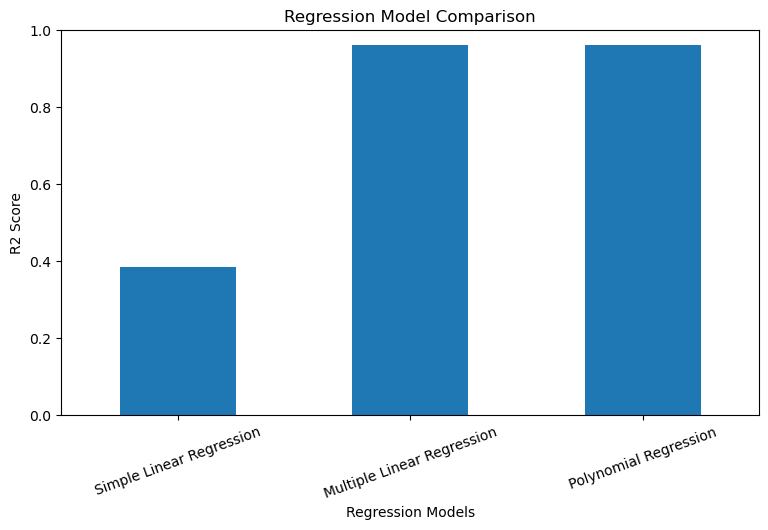

In [90]:

# Compare R2 scores

regression_comparison['R2 Score'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Regression Model Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.show()


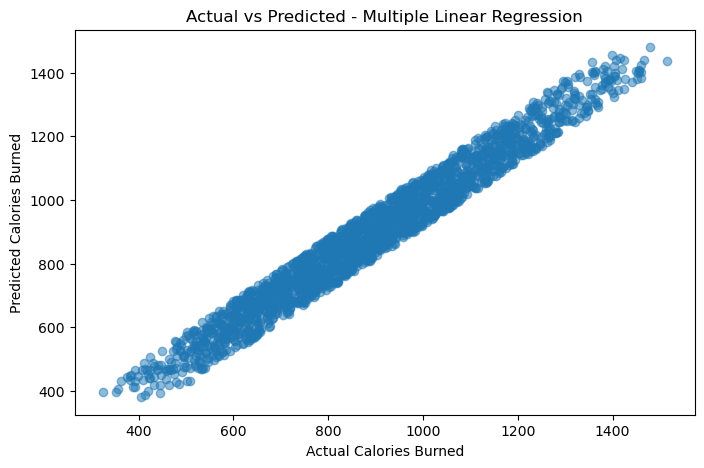

In [91]:

# Actual vs Predicted values for MLR

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_mlr,
    mlr_pred,
    alpha=0.5
)

plt.xlabel("Actual Calories Burned")
plt.ylabel("Predicted Calories Burned")

plt.title("Actual vs Predicted - Multiple Linear Regression")

plt.show()


In [92]:

# Select the model with the highest R2 score

best_model = regression_comparison['R2 Score'].idxmax()

print("Best Regression Model:", best_model)

print("\nFinal Model Selection: Multiple Linear Regression")

print(
    "MLR R2 Score:",
    round(mlr_results[3], 4)
)


Best Regression Model: Polynomial Regression

Final Model Selection: Multiple Linear Regression
MLR R2 Score: 0.9613


Final Model Selection – Multiple Linear Regression

After comparing Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression, Multiple Linear Regression was selected as the final regression model for predicting calories burned.

Simple Linear Regression showed comparatively lower performance because it considered only workout duration as an independent variable. Polynomial Regression achieved a marginally higher R² score than Multiple Linear Regression, but the improvement was negligible.

Multiple Linear Regression achieved an R² score of approximately 0.9613, indicating that it explains around 96.13% of the variation in the target variable on the test dataset. It also provides a good balance between prediction performance, model simplicity, and interpretability.

Therefore, Multiple Linear Regression was selected as the final regression model for the CampusFit project.

## K-Nearest Neighbors (KNN) Classification

In [93]:

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


In [94]:
#Train KNN model

# Create KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test_scaled)


In [95]:
# Evaluate the model

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)

knn_recall = recall_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)

knn_f1 = f1_score(
    y_test, y_pred_knn, average='weighted', zero_division=0
)

knn_macro_f1 = f1_score(
    y_test, y_pred_knn, average='macro', zero_division=0
)

print("KNN Model Evaluation")
print("--------------------")
print("Accuracy:", knn_accuracy)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 Score:", knn_f1)
print("Macro F1 Score:", knn_macro_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))


KNN Model Evaluation
--------------------
Accuracy: 0.896
Precision: 0.8533175891046073
Recall: 0.896
F1 Score: 0.8587880553674353
Macro F1 Score: 0.3546783469023502

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      1794
           1       0.46      0.07      0.12       190
           2       0.00      0.00      0.00        16

    accuracy                           0.90      2000
   macro avg       0.46      0.35      0.35      2000
weighted avg       0.85      0.90      0.86      2000



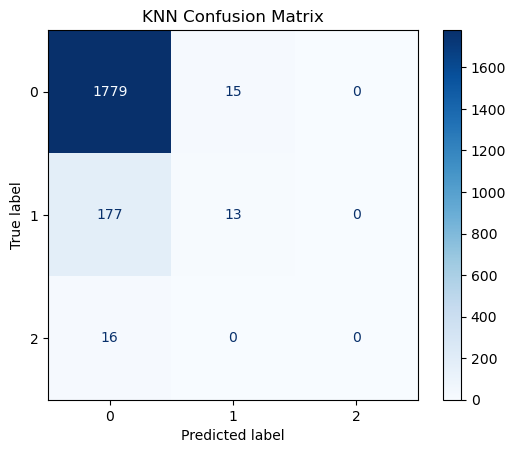

In [96]:

cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn)

disp.plot(cmap='Blues')

plt.title("KNN Confusion Matrix")
plt.show()


## Naive Bayes Classification

In [99]:
from sklearn.naive_bayes import GaussianNB

In [100]:
# Train Naive Bayes

# Create Gaussian Naive Bayes classifier
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_scaled)


In [101]:
# Evaluating

# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test, y_pred_nb, average='weighted', zero_division=0
)

nb_recall = recall_score(
    y_test, y_pred_nb, average='weighted', zero_division=0
)

nb_f1 = f1_score(
    y_test, y_pred_nb, average='weighted', zero_division=0
)

nb_macro_f1 = f1_score(
    y_test, y_pred_nb, average='macro', zero_division=0
)

print("Naive Bayes Model Evaluation")
print("----------------------------")
print("Accuracy:", nb_accuracy)
print("Precision:", nb_precision)
print("Recall:", nb_recall)
print("F1 Score:", nb_f1)
print("Macro F1 Score:", nb_macro_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))


Naive Bayes Model Evaluation
----------------------------
Accuracy: 0.981
Precision: 0.988851867887939
Recall: 0.981
F1 Score: 0.9829869411742012
Macro F1 Score: 0.8128535023929393

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1794
           1       0.99      0.81      0.89       190
           2       0.38      1.00      0.55        16

    accuracy                           0.98      2000
   macro avg       0.79      0.94      0.81      2000
weighted avg       0.99      0.98      0.98      2000



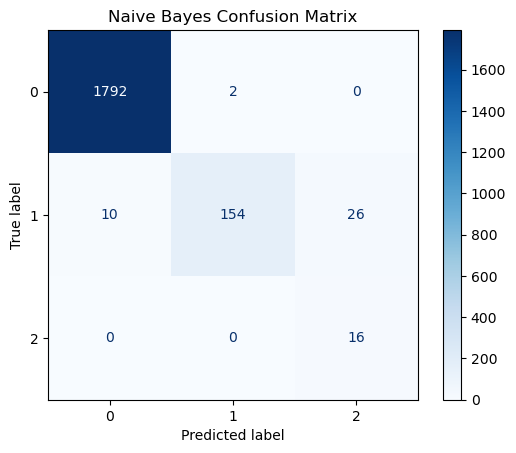

In [102]:

cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_nb)

disp.plot(cmap='Blues')

plt.title("Naive Bayes Confusion Matrix")
plt.show()


### KNN VS NAIVE BAYES

In [103]:

model_comparison = pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes'],
    'Accuracy': [knn_accuracy, nb_accuracy],
    'Precision': [knn_precision, nb_precision],
    'Recall': [knn_recall, nb_recall],
    'F1 Score': [knn_f1, nb_f1],
    'Macro F1 Score': [knn_macro_f1, nb_macro_f1]
})

model_comparison


,Model,Accuracy,Precision,Recall,F1 Score,Macro F1 Score
0,KNN,0.896,0.853318,0.896,0.858788,0.354678
1,Naive Bayes,0.981,0.988852,0.981,0.982987,0.812854


## Comparative Analysis of Classification Models

In [108]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store predictions from all four models
predictions = {
    'Decision Tree': y_pred,
    'Random Forest': rf_pred,
    'KNN': y_pred_knn,
    'Naive Bayes': y_pred_nb
}

# Calculate evaluation metrics
comparison_results = []

for model_name, model_predictions in predictions.items():

    comparison_results.append({
        'Model': model_name,

        'Accuracy': accuracy_score(y_test, model_predictions),

        'Precision': precision_score(
            y_test, model_predictions,
            average='weighted', zero_division=0
        ),

        'Recall': recall_score(
            y_test, model_predictions,
            average='weighted', zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, model_predictions,
            average='weighted', zero_division=0
        ),

        'Macro F1 Score': f1_score(
            y_test, model_predictions,
            average='macro', zero_division=0
        )
    })

classification_comparison = pd.DataFrame(comparison_results)

classification_comparison


,Model,Accuracy,Precision,Recall,F1 Score,Macro F1 Score
0,Decision Tree,1.0000,1.000000,1.0000,1.000000,1.000000
1,Random Forest,0.9985,0.998523,0.9985,0.998428,0.962906
2,KNN,0.8960,0.853318,0.8960,0.858788,0.354678
3,Naive Bayes,0.9810,0.988852,0.9810,0.982987,0.812854


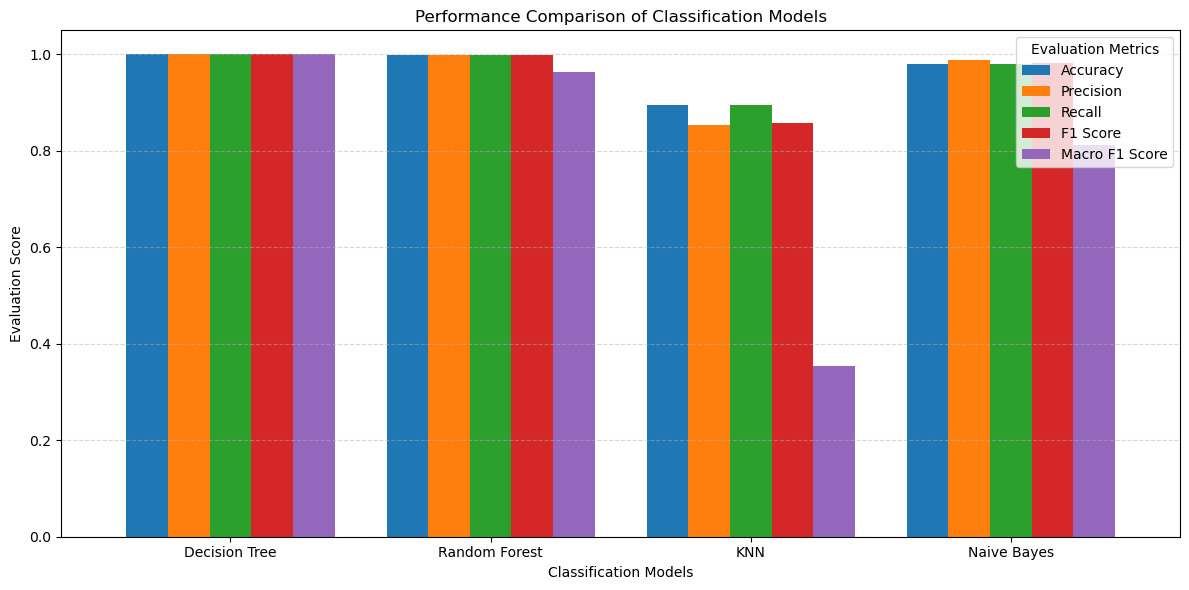

In [109]:

import matplotlib.pyplot as plt

# Select evaluation metrics
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'Macro F1 Score'
]

# Create bar chart
classification_comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


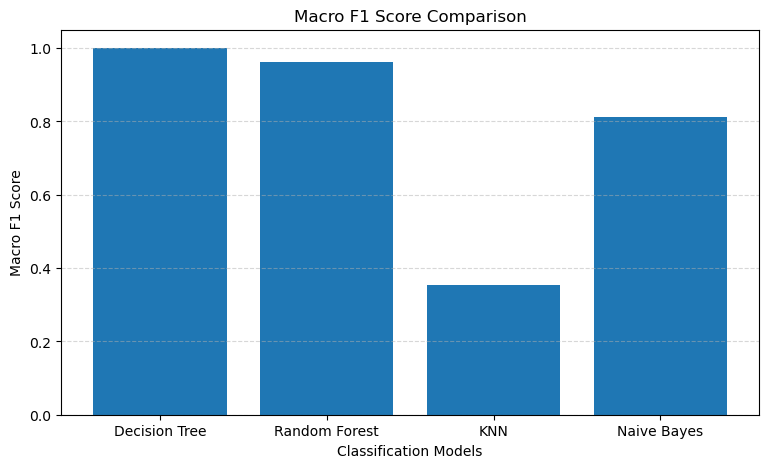

In [110]:

plt.figure(figsize=(9, 5))

plt.bar(
    classification_comparison['Model'],
    classification_comparison['Macro F1 Score']
)

plt.title('Macro F1 Score Comparison')
plt.xlabel('Classification Models')
plt.ylabel('Macro F1 Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


In [111]:

best_model = classification_comparison.loc[
    classification_comparison['Macro F1 Score'].idxmax()
]

print("Best Performing Model:", best_model['Model'])
print("Macro F1 Score:", round(best_model['Macro F1 Score'], 4))


Best Performing Model: Decision Tree
Macro F1 Score: 1.0



# Final Results and Conclusion


In [113]:

# Identify the best classification model
best_model = classification_comparison.loc[
    classification_comparison['Macro F1 Score'].idxmax()
]

print("FINAL CLASSIFICATION RESULTS")
print("=" * 40)

print("Best Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))
print("Macro F1 Score:", round(best_model['Macro F1 Score'], 4))


FINAL CLASSIFICATION RESULTS
Best Model: Decision Tree
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Macro F1 Score: 1.0


The CampusFit project demonstrates the application of data preprocessing, exploratory data analysis, feature engineering, and machine learning techniques to fitness-related data.

Multiple machine learning algorithms were implemented and evaluated for predicting user dropout risk, including Decision Tree, Random Forest, K-Nearest Neighbors, and Naive Bayes.

For regression analysis, Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression were compared to predict calories burned. Multiple Linear Regression was selected because it provides a strong balance between prediction performance, simplicity, and interpretability.

The classification models were evaluated using accuracy, precision, recall, weighted F1-score, and macro F1-score to understand their predictive performance.

Overall, CampusFit demonstrates how machine learning can be used to analyse fitness patterns, estimate calories burned, and identify potential dropout risks, supporting more informed fitness-related decisions.


## Additional Feature Selection Experiment

The notebook already applies SelectKBest (ANOVA F-test) to identify ten features. This additional experiment evaluates a Decision Tree trained only on those selected features, using the same train/test split, and compares its Macro F1 score with the baseline Decision Tree. This is an extra experiment; the existing analysis and results remain unchanged.


In [ ]:
# Train and evaluate a Decision Tree using the selected 10 features
from sklearn.metrics import f1_score, accuracy_score

selected_dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)
selected_dt_model.fit(X_train_selected, y_train)
selected_dt_pred = selected_dt_model.predict(X_test_selected)

selected_accuracy = accuracy_score(y_test, selected_dt_pred)
selected_macro_f1 = f1_score(y_test, selected_dt_pred, average='macro', zero_division=0)

print('Decision Tree with Top 10 Selected Features')
print('Accuracy:', round(selected_accuracy, 4))
print('Macro F1 Score:', round(selected_macro_f1, 4))
print('Selected features:', selected_features.tolist())
